In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.linear_model import LinearRegression


data_dir = Path('../datasets/ts-course-data/')
comp_dir = Path('../datasets/store-sales-time-series-forecasting')

book_sales = pd.read_csv(
    data_dir / 'book_sales.csv',
    index_col='Date',
    parse_dates=['Date'],
).drop('Paperback', axis=1)
book_sales['Time'] = np.arange(len(book_sales.index))
book_sales['Lag_1'] = book_sales['Hardcover'].shift(1)
book_sales = book_sales.reindex(columns=['Hardcover', 'Time', 'Lag_1'])

ar = pd.read_csv(data_dir / 'ar.csv')

dtype = {
    'store_nbr': 'category',
    'family': 'category',
    'sales': 'float32',
    'onpromotion': 'uint64',
}
store_sales = pd.read_csv(
    comp_dir / 'train.csv',
    dtype=dtype,
    parse_dates=['date'],
)
store_sales = store_sales.set_index('date').to_period('D')
store_sales = store_sales.set_index(['store_nbr', 'family'], append=True)
average_sales = store_sales.groupby('date').mean()['sales']

In [2]:
from IPython.display import display, Markdown

content = f"""
Linear regressions models are explainable: it's easy to interpret what contribution each feature makes
to the predictions. In the model `target = weight * feature + bias`, the `weight` tells you by how much the target
changes on average for each unit of change in the feature.
"""
display(Markdown(content))


Linear regressions models are explainable: it's easy to interpret what contribution each feature makes
to the predictions. In the model `target = weight * feature + bias`, the `weight` tells you by how much the target
changes on average for each unit of change in the feature.


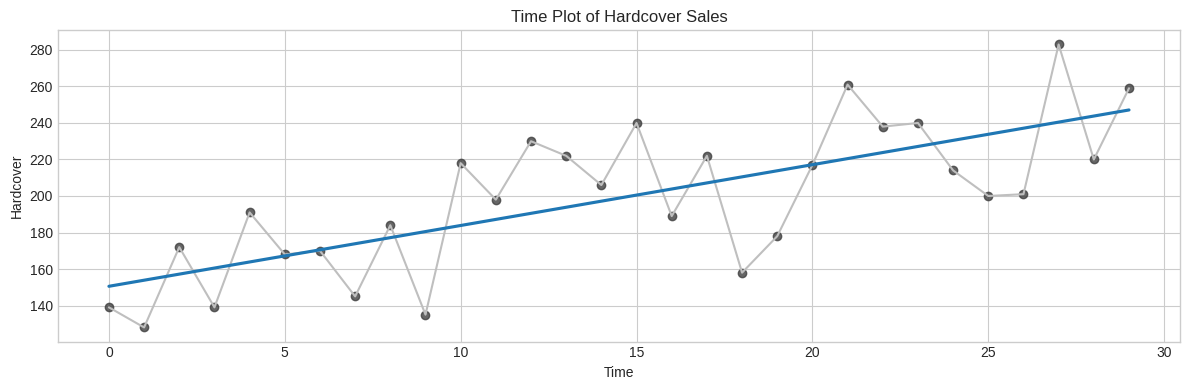

In [3]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(12, 4), titlesize=18, titleweight='bold')
fig, ax = plt.subplots()
ax.plot('Time', 'Hardcover', data=book_sales, color='0.75')
ax = sns.regplot(x='Time', y='Hardcover', data=book_sales, ci=None, scatter_kws=dict(color='0.25'))
ax.set_title('Time Plot of Hardcover Sales');

In [4]:
content = f"""
**Q**: **The linear regression line has an equation of (approximately) `Hardcover = 3.33 * Time + 150.5`. 
Over 6 days how much on average would you expect hardcover sales to change?**<br>
**A**: Correct: A change of 6 steps in `Time` corresponds to an average change of 6 * 3.33 = 19.98 in `Hardcover` sales.
"""

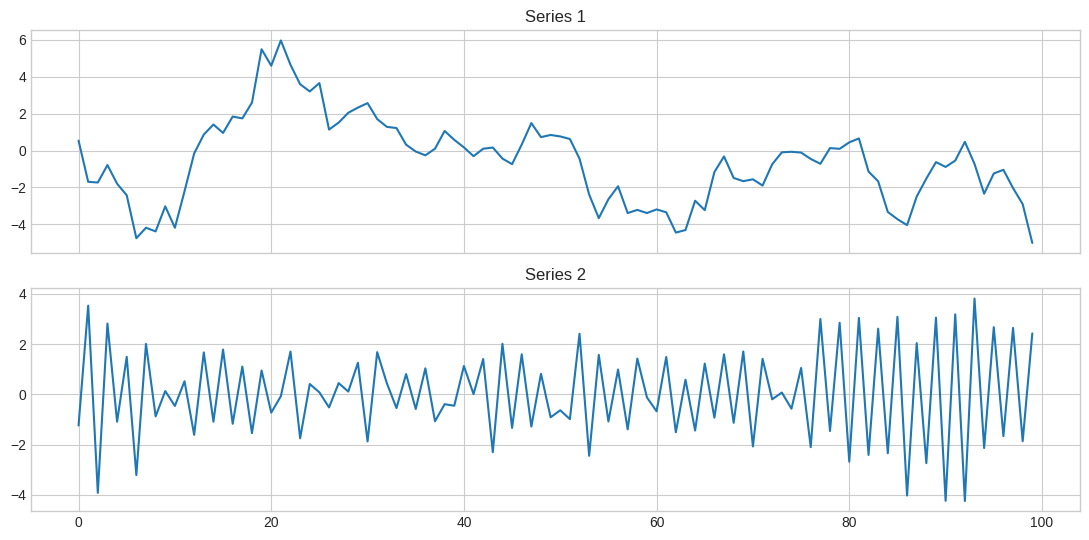

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax1.plot(ar['ar1'])
ax1.set_title('Series 1')
ax2.plot(ar['ar2'])
ax2.set_title('Series 2');

In [7]:
content = f"""
**Q**: **One of these series has the equation `target = 0.95 * lag_1 + error` and the other has the equation 
`target = -0.95 * lag_1 + error`, differing only by the sign on the lag feature. Can you tell which equation 
goes with each series?**<br>
**A**: *Series 1* was generated by `target = 0.95 * lag_1 + error` and *Series 2* was generated by 
`target = -0.95 * lag_1 + error`.
"""
display(Markdown(content))


**Q**: **One of these series has the equation `target = 0.95 * lag_1 + error` and the other has the equation 
`target = -0.95 * lag_1 + error`, differing only by the sign on the lag feature. Can you tell which equation 
goes with each series?**<br>
**A**: *Series 1* was generated by `target = 0.95 * lag_1 + error` and *Series 2* was generated by 
`target = -0.95 * lag_1 + error`.


In [11]:
sales_data = average_sales.to_frame()
sales_data['time'] = np.arange(len(sales_data.index))
sales_data

,sales,time
date,,
2013-01-01,1.409438,0
2013-01-02,278.390808,1
2013-01-03,202.840195,2
2013-01-04,198.911163,3
2013-01-05,267.873260,4
...,...,...
2017-08-11,463.733856,1679
2017-08-12,444.798309,1680
2017-08-13,485.768616,1681


In [14]:
from sklearn.linear_model import LinearRegression

sales_data = average_sales.to_frame()
sales_data['time'] = np.arange(len(sales_data.index))

X = sales_data.loc[:, ['time']]  # features
y = sales_data.loc[:, 'sales']   # target

# Train the model
model = LinearRegression()
model.fit(X, y)

# Store the fitted values as a time series with the same time index as
# the training data
y_pred = pd.Series(model.predict(X), index=X.index)
y_pred

date
2013-01-01    194.232790
2013-01-02    194.427137
2013-01-03    194.621484
2013-01-04    194.815831
2013-01-05    195.010178
                 ...    
2017-08-11    520.541320
2017-08-12    520.735667
2017-08-13    520.930014
2017-08-14    521.124361
2017-08-15    521.318708
Freq: D, Length: 1684, dtype: float64

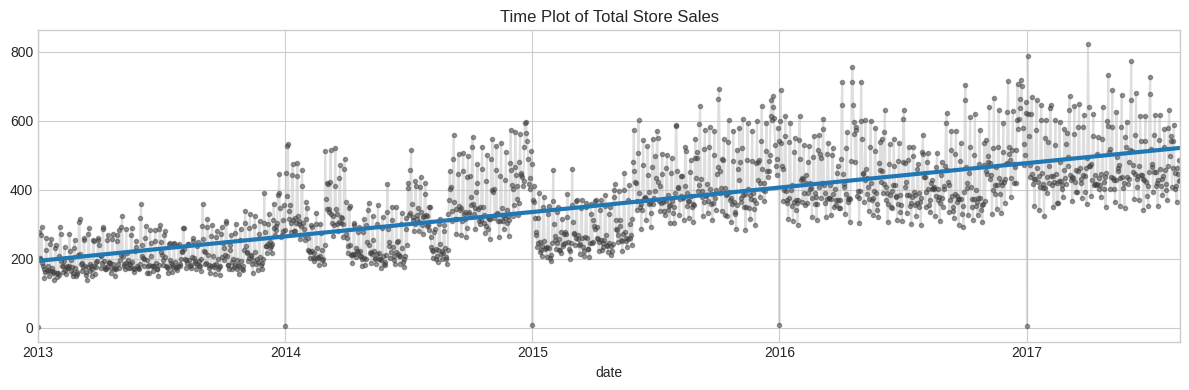

In [18]:
plot_params = {
    'color': '0.75',
    'style': '.-',
    'markeredgecolor': '0.25',
    'markerfacecolor': '0.25',
    'legend': False
}
ax = y.plot(**plot_params, alpha=0.5)
ax = y_pred.plot(ax=ax, linewidth=3)
ax.set_title('Time Plot of Total Store Sales');

In [20]:
sales_data = average_sales.to_frame()

# Create a lag feature from the target 'sales'
sales_data['lag_1'] = sales_data['sales'].shift(1)


X = sales_data.loc[:, ['lag_1']].dropna()  # features
y = sales_data.loc[:, 'sales']  # target
y, X = y.align(X, join='inner')  # drop corresponding values in target

# Create a LinearRegression instance and fit it to X and y.
model = LinearRegression()
model.fit(X, y)

# Create Store the fitted values as a time series with
# the same time index as the training data
y_pred = pd.Series(model.predict(X), index=X.index)

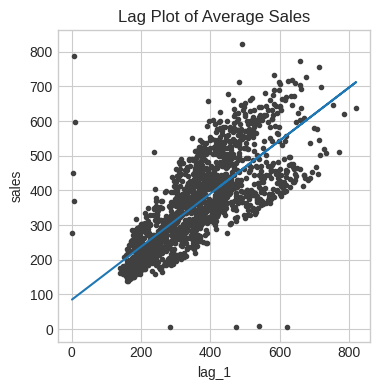

In [21]:
fig, ax = plt.subplots()
ax.plot(X['lag_1'], y, '.', color='0.25')
ax.plot(X['lag_1'], y_pred)
ax.set(aspect='equal', ylabel='sales', xlabel='lag_1', title='Lag Plot of Average Sales');